### Q2.1

In [39]:
import hashlib

# 1. Get the username part of your email
username = "ritama.sanyal"

# 2. Generate the seed using the provided formula
your_seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)

print(f"Your personalized random seed is: {your_seed}")

Your personalized random seed is: 284869898


In [40]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load the dataset
# Assuming the columns are ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
df = pd.read_csv('Clustering_dataset_q2.csv')
df.dropna(inplace=True)
# --- Preprocessing ---

# 1. One-Hot Encode the 'Gender' column
df_processed = pd.get_dummies(df, columns=['Gender'], drop_first=True)

# 2. Select features for clustering and scale them
# We'll use Age, Annual Income, Spending Score, and the new Gender column
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Male']
X = df_processed[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape of preprocessed data:", X_scaled.shape)

Shape of preprocessed data: (178, 4)


In [41]:
import numpy as np

class KMeans:
    """
    A custom implementation of the K-Means clustering algorithm from scratch.
    """

    def __init__(self, k=3, max_iter=100):
        """
        Initializes the KMeans model.

        Args:
            k (int): The number of clusters to form.
            max_iter (int): The maximum number of iterations for the algorithm to run.
        """
        self.k = k
        self.max_iter = max_iter
        self.centroids = None
        self._clusters = None
        self.X_fit = None

    def _euclidean_distance(self, p1, p2):
        """
        Helper method to calculate the squared Euclidean distance between two points.

        Args:
            p1 (np.ndarray): The first data point.
            p2 (np.ndarray): The second data point.

        Returns:
            float: The squared Euclidean distance between the two points.
        """
        return np.sum((p1 - p2)**2)

    def fit(self, X):
        """
        Trains the K-Means model on the dataset. This involves initializing centroids
        and iteratively updating them until convergence or max_iter is reached.

        Args:
            X (np.ndarray): The training data of shape (n_samples, n_features).
        """
        self.X_fit = X
        n_samples, n_features = self.X_fit.shape

        # 1. Initialize centroids randomly
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = self.X_fit[random_indices]

        # --- Main Optimization Loop ---
        for _ in range(self.max_iter):
            # 2. Assign samples to the closest centroid (Assignment Step)
            self._clusters = [[] for _ in range(self.k)]
            for idx, sample in enumerate(self.X_fit):
                distances = [self._euclidean_distance(sample, point) for point in self.centroids]
                closest_centroid_idx = np.argmin(distances)
                self._clusters[closest_centroid_idx].append(idx)

            # 3. Update centroids to be the mean of assigned samples (Update Step)
            new_centroids = np.zeros((self.k, n_features))
            for cluster_idx, cluster in enumerate(self._clusters):
                if cluster: # Avoid division by zero for empty clusters
                    cluster_mean = np.mean(self.X_fit[cluster], axis=0)
                    new_centroids[cluster_idx] = cluster_mean
                else: # Handle empty clusters by re-initializing
                    new_centroids[cluster_idx] = self.X_fit[np.random.choice(n_samples)]

            # 4. Check for convergence (if centroids don't change)
            if np.allclose(self.centroids, new_centroids):
                break
            
            self.centroids = new_centroids

    def predict(self, X):
        """
        Assigns each data point to the nearest cluster based on the fitted centroids.

        Args:
            X (np.ndarray): Data to predict clusters for.
            
        Returns:
            np.ndarray: An array of cluster labels for each data point.
        """
        if self.centroids is None:
            raise RuntimeError("Model has not been fitted yet. Call fit() first.")
            
        predictions = []
        for sample in X:
            distances = [self._euclidean_distance(sample, point) for point in self.centroids]
            predictions.append(np.argmin(distances))
        
        return np.array(predictions)

    def getCost(self):
        """
        Calculates and returns the Within-Cluster Sum of Squares (WCSS),
        which is the total sum of squared distances between each point and its assigned centroid.

        Returns:
            float: The total WCSS cost.
        """
        if self.centroids is None or self._clusters is None or self.X_fit is None:
            raise RuntimeError("Model has not been fitted yet. Call fit() first.")

        cost = 0
        for i, cluster in enumerate(self._clusters):
            centroid = self.centroids[i]
            cluster_cost = np.sum([self._euclidean_distance(self.X_fit[sample_idx], centroid) for sample_idx in cluster])
            cost += cluster_cost
            
        return cost

In [ ]:
# --- Using the Custom KMeans Class ---

# Instantiate the model with k=5 
kmeans = KMeans(k=5, max_iter=100)

# Train the model on the scaled data
kmeans.fit(X_scaled)

# Get the cluster assignments for each data point
predictions = kmeans.predict(X_scaled)
print("Sample predictions (cluster labels):", predictions[:10])

# Calculate and print the cost (WCSS)
cost = kmeans.getCost()
print(f"Within-Cluster Sum of Squares (WCSS): {cost:.2f}")

Sample predictions (cluster labels): [2 2 2 2 2 0 2 1 2 1]
Within-Cluster Sum of Squares (WCSS): 298.58


### Q2.2

#### ELBOW METHOD

Running Elbow Method...
  k=2, WCSS=522.72
  k=3, WCSS=424.13
  k=4, WCSS=344.88
  k=5, WCSS=319.08
  k=6, WCSS=268.60
  k=7, WCSS=208.06
  k=8, WCSS=204.20
  k=9, WCSS=194.00
  k=10, WCSS=167.04
  k=11, WCSS=124.47
  k=12, WCSS=130.99
  k=13, WCSS=126.10
  k=14, WCSS=110.21
  k=15, WCSS=112.67
  k=16, WCSS=97.64
  k=17, WCSS=92.75
  k=18, WCSS=95.24
  k=19, WCSS=86.90


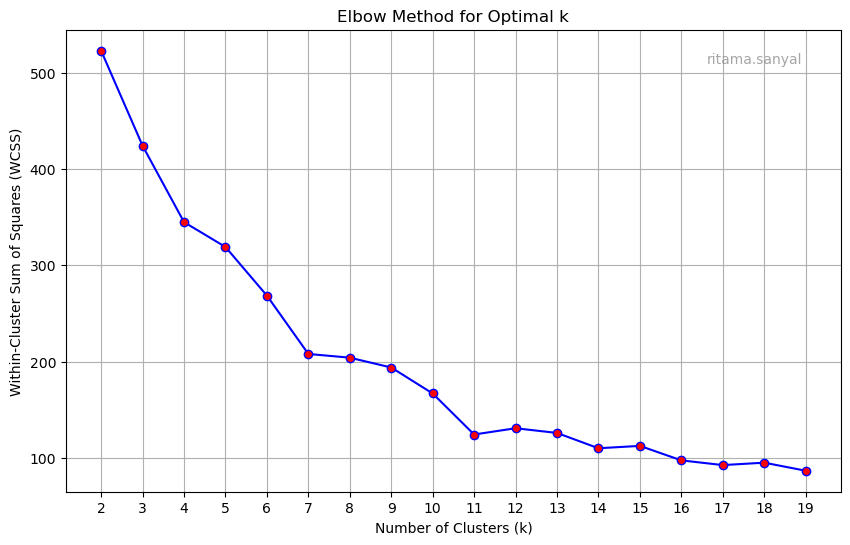

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# --- Elbow Method ---

# Set your personalized seed for reproducibility
np.random.seed(your_seed)

k_values = range(2, 20)
wcss_values = []

print("Running Elbow Method...")
for k in k_values:
    # Instantiate and train your model for the current k
    kmeans = KMeans(k=k, max_iter=100)
    kmeans.fit(X_scaled)
    
    # Get the WCSS and append it to our list
    wcss = kmeans.getCost()
    wcss_values.append(wcss)
    print(f"  k={k}, WCSS={wcss:.2f}")

# Plot the WCSS against k
plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_values, 'bo-', markerfacecolor='r')

# Add plot labels and your username as required by the assignment
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(k_values)
plt.grid(True)
plt.text(0.95, 0.95, "ritama.sanyal", ha='right', va='top', 
         transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
plt.show()

Based on the Elbow Method plot, the optimal number of clusters (**k**) is **7**.  

---

## Analysis of the Elbow Plot

The goal of the **Elbow Method** is to identify the point on the WCSS (Within-Cluster Sum of Squares) curve where the rate of decrease slows significantly, forming a clear "elbow."  
This point indicates that adding more clusters beyond it provides only marginal improvement.  

In the plot:

- There is a **steep and consistent decrease** in WCSS from *k = 2* up to *k = 7*.  
- After **k = 7**, the curve **flattens dramatically**. For example, WCSS decreases only from **208.06 at k = 7** to **204.20 at k = 8**, which is a much smaller improvement compared to earlier steps.  

---

### Conclusion
The distinct bend at **k = 7** marks the **elbow point**, representing the best balance between the number of clusters and t


#### SILLOUTE METHOD


Running Silhouette Method...
  k=2, Silhouette Score=0.2522
  k=3, Silhouette Score=0.2583
  k=4, Silhouette Score=0.2945
  k=5, Silhouette Score=0.2830
  k=6, Silhouette Score=0.3028
  k=7, Silhouette Score=0.3577
  k=8, Silhouette Score=0.3388
  k=9, Silhouette Score=0.3077
  k=10, Silhouette Score=0.3561
  k=11, Silhouette Score=0.4133
  k=12, Silhouette Score=0.3770
  k=13, Silhouette Score=0.3561
  k=14, Silhouette Score=0.3969
  k=15, Silhouette Score=0.3715
  k=16, Silhouette Score=0.3701
  k=17, Silhouette Score=0.3734
  k=18, Silhouette Score=0.3428
  k=19, Silhouette Score=0.3620


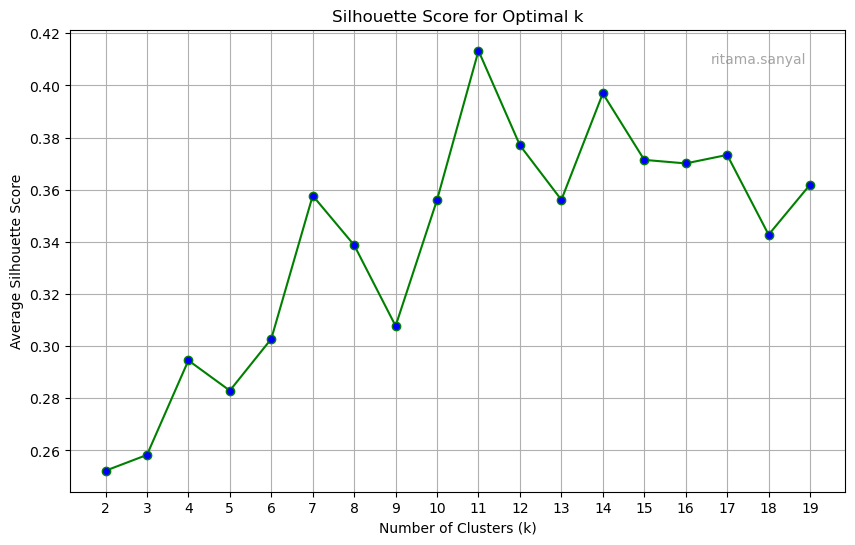

In [44]:
from sklearn.metrics import silhouette_score

# --- Silhouette Method ---

# Set the same seed to ensure the k-means runs are comparable
np.random.seed(your_seed)

# Use the same range for k
silhouette_scores = []

k_values = range(2, 20)
print("\nRunning Silhouette Method...")
for k in k_values:
    # Instantiate and train your model
    kmeans = KMeans(k=k, max_iter=100)
    kmeans.fit(X_scaled)
    
    # Predict the cluster labels for each data point
    labels = kmeans.predict(X_scaled)
    
    # Calculate the average silhouette score and append it
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"  k={k}, Silhouette Score={score:.4f}")
    
# Plot the silhouette score for each k
plt.figure(figsize=(10, 6))
plt.plot(k_values, silhouette_scores, 'go-', markerfacecolor='b')

# Add plot labels and your username
plt.title('Silhouette Score for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.xticks(k_values)
plt.grid(True)
plt.text(0.95, 0.95, "ritama.sanyal", ha='right', va='top', 
         transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
plt.show()

The clear optimal value for **k is 11**, which achieves the maximum silhouette score of approximately **0.4133**. 

---

## Interpreting the Clusters at *k = 11*

The **silhouette score** measures how dense and well-separated the clusters are.  
A score of **0.4133**, the highest observed in your tests, indicates that **k = 11** provides the best clustering structure for this dataset.

- **Good Separation**: A score of ~0.41 suggests that the 11 clusters are **reasonably distinct and well-separated**. On average, data points are much closer to their own cluster members than to those in neighboring clusters.  
- **Most Meaningful Grouping**: The result implies that the underlying distribution of the dataset is best captured by **11 distinct clusters**. While the score is not perfect (i.e., not close to 1.0), it strongly suggests that this is the most natural number of clusters for the data.  

---
### Conclusion
Choosing **k = 11** yields the **most meaningful and best-separated clustering** among all tested values, making it the optimal choice according to the silhouette method.


https://g.co/gemini/share/bee6f3df11b0